# Dispatch strategies

This notebook explains how the simulator chooses a car for each new request. It covers the rules that every strategy shares, then each strategy in turn, then a small example that runs all of them on the same input.

The code is in `elevator/dispatch/`. The requirements are in `docs/requirements.md`.

## 1. What a strategy decides

A request is assigned once, at the time it is made (FR-ASN-1, FR-ASN-5). The simulator calls one method on the chosen strategy:

```python
choose_best_car_by_strategy(request, cars) -> Car | None
```

The strategy returns one car, or `None` if no car qualifies. Every strategy implements the same method (NFR-D1), so the simulator core does not change when a strategy is added.

Before a strategy is called, the request queue has already narrowed the list of cars, using the eligibility tiers in section 2.

## 2. Eligibility tiers (FR-ASN-6)

The request queue (`elevator/simulator/request_queue.py`) filters the cars in three tiers. The first tier with any car is used:

1. Express cars that serve both floors of the request and can take the passenger now.
2. Express cars that serve both floors, even if they must turn around first.
3. Every car.

Because a regular car serves every floor, tier 3 always has at least one car that can serve the request. This is why a strategy never has to handle a request that no car can serve.

## 3. Can a car take the passenger now?

`Car.can_honor_elevator_constraints(source, wanted)` is the "ready" test (FR-ASN-3). A car is ready when:

- it has room for one more passenger, and
- either it is empty (no riders and no unboarded passengers), or it is committed to the passenger's direction and the passenger is at or ahead of it in that direction.

An empty car is ready for any passenger. A car going up with a passenger ahead of it is ready for an UP passenger at or above it.

Round Robin and the two floor-based Nearest Car strategies prefer ready cars. The time-based strategies do not .

## 4. The forward run

The time-based strategies need to know when a car would pick a passenger up. They do not guess. `TripEstimator` (`elevator/dispatch/trip_estimator.py`) copies the car and runs the copy forward, one tick at a time, using the same `run_step` as the real simulation:

- `predict_pickup_time(car, request)` returns the tick at which the new passenger boards, or `None` if the car cannot serve the request.
- `predict_trips(car, request)` returns the predicted trips for the car, with the new request last. Cost Based uses this to find each passenger's wait.

The copy is thrown away after the prediction, so the real car is never changed. A copy does not log or count floors travelled.

Because it uses `run_step`, the forward run includes stops, seat limits, turns and the LOOK direction rule. That is why it is exact for the simulator's rules, and why it costs more than a formula.

## 5. The strategies

### 5.1 Round Robin (FR-ASN-4a)

**Idea:** take the cars in turn, so every car gets work.

**How it works:** the strategy keeps a pointer to the next car. It makes three passes, each starting at the pointer:

1. a car that is ready now;
2. a car with room, whatever its direction, since it will turn around;
3. any car that serves both floors.

The first car found wins, and the pointer moves past it. Requests made at the same time, in the same direction, can share a car if it has room for all of them (`group_for`).

**Does it measure distance or time?** No. It measures direction and room only.

**Code:** `round_robin_strategy.py`

### 5.2 Nearest Car, floor estimate (`NEAREST_CAR`, FR-ASN-4b-E)

**Idea:** the car that is closest in floors, counting the detour if it is heading away.

**Distance:** if the car is idle, or heading toward the passenger, the distance is `|car floor - source|`. If it is heading away, the distance is `|car floor - turn| + |turn - source|`, where the turn point is the furthest floor the car must reach in its current direction.

**How it works:** the candidates are the cars that serve both floors. Ready cars are preferred, and the smallest distance wins. Ties go to the lower car number.

**Limitation:** this is an estimate. It does not count stops, seats, or time spent at a floor.

**Code:** `nearest_car_strategy.py`

### 5.3 Nearest Car, simple (`NEAREST_CAR_SIMPLE`, FR-ASN-4b-S)

**Idea:** the car that is closest in floors, with no direction taken into account. It is kept as a comparison baseline.

**Distance:** `|car floor - source|`.

**How it works:** the same as 5.2, except the distance ignores direction.

**Limitation:** a car heading away from the passenger can look close. In the morning sample, this strategy sent one car across 48 floors, which gave the longest waits of any strategy.

**Code:** `nearest_car_simple_strategy.py`

### 5.4 Nearest Car, forward run (`NEAREST_CAR_FORWARD_RUN`, FR-ASN-4b)

**Idea:** the car that picks the passenger up soonest, measured in ticks by a forward run.

**Score:** `predict_pickup_time(car, request) - request.request_time`, the wait in ticks.

**How it works:** every eligible car is tested. The car with the smallest wait wins. Ties go to the lower car number.

**Strength:** exact for the simulator's rules.

**Cost:** one forward run per eligible car, for every request.

**Code:** `nearest_car_forward_run_strategy.py`

### 5.5 Cost Based (`COST_BASED`, FR-ASN-4c)

**Idea:** keep waits balanced, so that no passenger is left far behind.

**Score:** for each eligible car, `predict_trips` gives the waits of every passenger the car would carry after the assignment, including the new one. The car's score is the longest of those waits.

**How it works:** the car with the smallest longest wait wins. Ties go to the lower car number.

**Effect:** the strategy aims at the worst case, not the average. On the big file in evening mode it had the lowest average total (31.6 steps) and the smallest longest total (77 steps, against 265 for Nearest Car Forward Run). On the big file in normal mode, its average was worse than Nearest Car Forward Run (40.3 against 36.6 steps), so it does not win on every file.

**Code:** `cost_based_strategy.py`

### 5.6 Balanced (`BALANCED_STRATEGY`, FR-ASN-4d)

**Idea:** trade off how soon a car can pick the passenger up against how many passengers it already carries.

**Score:** `wait_time_weight x wait + car_load_weight x (riders + unboarded)`, where `wait` is `predict_pickup_time - request_time`. Both weights are 1.0 by default and are set in the code.

**How it works:** the car with the lowest score wins. Ties go to the lower car number.

**Effect:** with `car_load_weight = 0` it is the same as Nearest Car Forward Run. A larger load weight spreads passengers over more cars.

**Code:** `balanced_strategy.py`

## 6. Comparison

| Strategy | Measures | Uses forward run | Prefers ready cars | Groups requests |
|---|---|---|---|---|
| Round Robin | rotation, direction, room | no | yes | yes (same time, same direction) |
| Nearest Car (floor estimate) | floors, with turn detour | no | yes | no |
| Nearest Car, simple | floors only | no | yes | no |
| Nearest Car, forward run | ticks to pickup | yes | no | no |
| Cost Based | longest predicted wait | yes | no | no |
| Balanced | ticks to pickup plus load | yes | no | no |

Choose the strategy in `elevator.properties` with `strategy=`. `strategy=ALL` runs every strategy on the same requests, and writes one position log and one summary section per strategy.

## 7. Small sample: measures for each strategy

This section runs every strategy on the same small input, so their results can be compared directly. It uses 12 passengers, 10 floors and 3 cars with capacity 4. The cars start on floors 1, 5 and 10. The table has one column per strategy.

- **Wait** is the time from the request until pickup, in ticks. **Total time** is wait plus travel time (OBJ-2).
- **Median** is the middle value. **Std** is the population standard deviation, as in the summary (FR-OUT-3).
- **Total floors travelled** is the number of floors all cars moved.
- **Passengers per car** is the number of passengers each car was given, in car-number order.
- **Passenger balance across cars** (Jain's index) measures how evenly the passengers are spread over the cars. It is `(Σx)² / (n × Σx²)`, where `x` is the passengers per car and `n` is the number of cars. It is 1 when every car carries the same number, and it falls toward `1/n` when one car carries everything.

The average travel time is the same for every strategy in this model, because a car carrying riders always moves toward their destinations without stopping. Only the waits differ, so the total times differ by the wait.

In [ ]:
import io
import statistics

from elevator.config.sim_config import CarSpec, SimConfig, Strategy, TrafficMode
from elevator.dispatch.dispatch_strategy import DispatchStrategy
from elevator.files.output_writer import OutputWriter
from elevator.files.request_reader import RequestReader
from elevator.simulator.simulation import Simulation

sample = """time, id, source, dest
0, c, 7, 5
2, i, 10, 1
3, d, 4, 1
4, e, 5, 6
4, g, 1, 4
5, a, 8, 5
6, b, 4, 8
7, j, 8, 10
9, h, 5, 1
10, f, 3, 10
10, k, 5, 4
12, l, 5, 6
"""
requests = RequestReader.read(io.StringIO(sample), 10)
cars = [CarSpec(4, 1, 1, None), CarSpec(4, 5, 1, None), CarSpec(4, 10, 1, None)]


def jain_index(values):
    """Jain's fairness index: 1 when every value is equal, 1/n when one value holds everything."""
    n = len(values)
    return sum(values) ** 2 / (n * sum(v * v for v in values))


# To count passengers per car, record the car each passenger is given. The simulator creates its strategy
# with DispatchStrategy.create, so this wraps that strategy and keeps the chosen car numbers.
chosen_cars = []
original_create = DispatchStrategy.create


class RecordingStrategy(DispatchStrategy):
    def __init__(self, inner):
        self._inner = inner

    def choose_best_car_by_strategy(self, request, cars_):
        car = self._inner.choose_best_car_by_strategy(request, cars_)
        chosen_cars.append(cars_.index(car))
        return car

    def group_for(self, car, request, unassigned_requests):
        return self._inner.group_for(car, request, unassigned_requests)


results = {}
for strategy in Strategy:
    chosen_cars.clear()
    DispatchStrategy.create = staticmethod(lambda config, estimator: RecordingStrategy(original_create(config, estimator)))
    config = SimConfig(10, cars, strategy, TrafficMode.NORMAL, None)
    simulation = Simulation(config, requests, OutputWriter(io.StringIO()))
    trips = simulation.run_simulation()
    waits = [trip.wait_time for trip in trips]
    totals = [trip.total_time for trip in trips]
    per_car = [chosen_cars.count(i) for i in range(len(cars))]
    results[strategy.name] = {
        "Min wait": min(waits),
        "Max wait": max(waits),
        "Median wait": statistics.median(waits),
        "Std wait": round(statistics.pstdev(waits), 2),
        "Min total time": min(totals),
        "Max total time": max(totals),
        "Median total time": statistics.median(totals),
        "Average total time": round(statistics.mean(totals), 2),
        "Std total time": round(statistics.pstdev(totals), 2),
        "Total floors travelled": sum(simulation.floors_travelled_per_car),
        "Passengers per car": ", ".join(str(n) for n in per_car),
        "Passenger balance across cars": round(jain_index(per_car), 3),
    }
DispatchStrategy.create = staticmethod(original_create)

names = list(results)
print(f"{'Measure':24}" + "".join(f"{name:>25}" for name in names))
for measure in results[names[0]]:
    print(f"{measure:24}" + "".join(f"{results[name][measure]:>25}" for name in names))

Measure                               ROUND_ROBIN              NEAREST_CAR  NEAREST_CAR_FORWARD_RUN       NEAREST_CAR_SIMPLE               COST_BASED        BALANCED_STRATEGY
Min wait                                        0                        0                        0                        0                        0                        0
Max wait                                       16                       14                        8                       14                        8                       14
Median wait                                   4.0                      2.0                      1.5                      2.0                      3.5                      1.5
Std wait                                     5.09                     4.87                     2.24                     4.69                     2.25                     4.37
Min total time                                  1                        2                        1                        2 

### 7.1 What the results show

The lines below are printed from the results in the table above, so they always match it.

In [ ]:
average = {name: row["Average total time"] for name, row in results.items()}
longest = {name: row["Max total time"] for name, row in results.items()}
jain = {name: row["Passenger balance across cars"] for name, row in results.items()}


def join(names):
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]


def its(names):
    return "Their" if len(names) > 1 else "Its"


most_even = max(jain.values())
even = [name for name in results if jain[name] == most_even]
fastest_average = min(average.values())
fast = [name for name in results if average[name] == fastest_average]
best_longest = min(longest.values())
best_worst = [name for name in results if longest[name] == best_longest]
worst_longest = max(longest.values())
worst = [name for name in results if longest[name] == worst_longest]

print(f"- Most even spread of passengers: {join(even)} (passenger balance {most_even}).")
print(f"- Lowest average total time: {join(fast)} ({fastest_average} ticks). "
      f"{its(fast)} longest total time is {longest[fast[0]]} ticks.")
print(f"- Shortest longest total time: {join(best_worst)} ({best_longest} ticks). "
      f"{its(best_worst)} average total time is {average[best_worst[0]]} ticks.")
print(f"- Longest total time: {join(worst)} ({worst_longest} ticks).")
if not set(fast) & set(best_worst):
    print("- The strategy with the lowest average total time is not the one with the shortest longest total time.")

- Most even spread of passengers: ROUND_ROBIN (passenger balance 0.984).
- Lowest average total time: NEAREST_CAR_FORWARD_RUN (5.33 ticks). Its longest total time is 11 ticks.
- Shortest longest total time: COST_BASED (10 ticks). Its average total time is 6.83 ticks.
- Longest total time: ROUND_ROBIN (19 ticks).
- The strategy with the lowest average total time is not the one with the shortest longest total time.


### 7.2 Samples where each strategy is best

We also ran a sample input for each strategy, in the `data/` folder. Each file was chosen so that its strategy is strictly best on one measure, so every strategy wins somewhere. These files show that each strategy can be the best on some input. They do not show that any strategy is best overall, and a different input can change the ranking.

| File | Strategy | Measure it is best on | Its value | Next-best strategy |
|---|---|---|---|---|
| `sample_best_round_robin.csv` | ROUND_ROBIN | Passenger balance across cars | 0.98 | 0.89 (Balanced) |
| `sample_best_nearest_car.csv` | NEAREST_CAR | Average total time | 9.75 | 10.58 (Forward Run) |
| `sample_best_nearest_car_forward_run.csv` | NEAREST_CAR_FORWARD_RUN | Average total time | 6.08 | 6.42 (Cost Based) |
| `sample_best_nearest_car_simple.csv` | NEAREST_CAR_SIMPLE | Average total time | 7.17 | 7.50 (Nearest Car) |
| `sample_best_cost_based.csv` | COST_BASED | Longest total time | 14 | 18 (Forward Run) |
| `sample_best_balanced_strategy.csv` | BALANCED_STRATEGY | Average total time | 9.00 | 9.50 (Cost Based) |

To run one of these, set `requests=` to the file name, with `floors=10`, `cars=3`, `capacity=4`, and all three cars starting on floor 1.

## 8. Fairness against efficiency

This section compares two goals on the sample in section 7:

- **Efficiency** serves the majority well, measured by the **average total time**.
- **Fairness** serves every passenger quickly, measured by the **longest total time**, the time the slowest passenger waits to be dropped off.

The plot below puts each strategy at one point: its average total time on the horizontal axis and its longest total time on the vertical axis. A strategy that is low and to the left is good on both goals. Where a strategy is high on one axis and low on the other, it trades one goal for the other.

On this sample:

- **Nearest Car Forward Run** has the lowest average total time (5.33 ticks), with a longest total time of 11 ticks.
- **Cost Based** has the shortest longest total time (10 ticks), with an average of 6.83 ticks.
- **Balanced** is close to Cost Based on average (6.67 ticks), with a longest total time of 16 ticks.
- **Nearest Car** and **Nearest Car Simple** have the same longest total time (18 ticks), with averages of 7.83 and 7.5 ticks.
- **Round Robin** has the longest total time on this sample (19 ticks), with an average of 8.75 ticks.

So the strategy with the lowest average total time, Nearest Car Forward Run, is not the one with the shortest longest total time, which is Cost Based. The choice depends on whether the building should optimise the typical passenger or limit the worst wait.

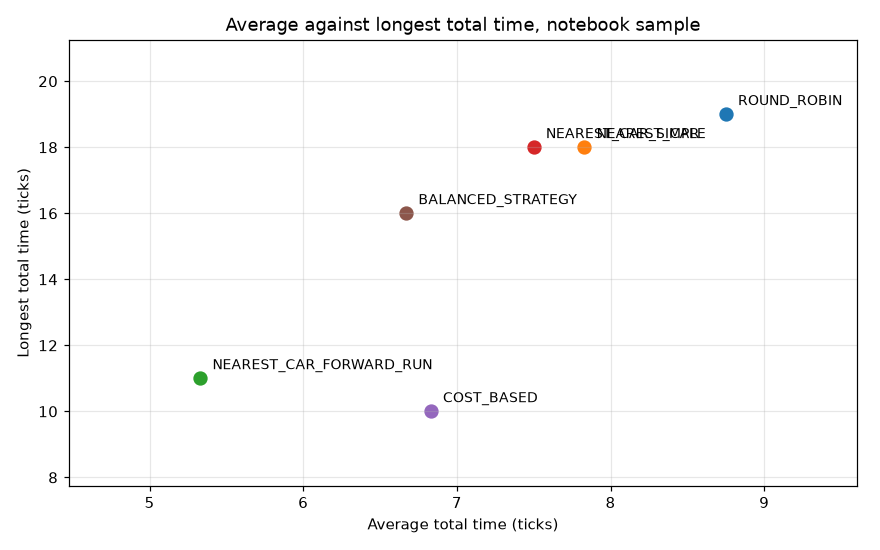

In [ ]:
import io
import matplotlib.pyplot as plt
import statistics

from elevator.config.sim_config import CarSpec, SimConfig, Strategy, TrafficMode
from elevator.files.output_writer import OutputWriter
from elevator.files.request_reader import RequestReader
from elevator.simulator.simulation import Simulation

sample = """time, id, source, dest
0, c, 7, 5
2, i, 10, 1
3, d, 4, 1
4, e, 5, 6
4, g, 1, 4
5, a, 8, 5
6, b, 4, 8
7, j, 8, 10
9, h, 5, 1
10, f, 3, 10
10, k, 5, 4
12, l, 5, 6
"""
requests = RequestReader.read(io.StringIO(sample), 10)
cars = [CarSpec(4, 1, 1, None), CarSpec(4, 5, 1, None), CarSpec(4, 10, 1, None)]

# Strategies that give the same result share one point, so their names are shown together.
points = {}
for strategy in Strategy:
    trips = Simulation(SimConfig(10, cars, strategy, TrafficMode.NORMAL, None), requests,
                       OutputWriter(io.StringIO())).run_simulation()
    totals = [trip.total_time for trip in trips]
    point = (round(statistics.mean(totals), 2), max(totals))
    points.setdefault(point, []).append(strategy.name)

fig, ax = plt.subplots(figsize=(8, 5))
for (average, longest), names in points.items():
    ax.scatter(average, longest, s=70)
    ax.annotate("\n".join(names), (average, longest), textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xlabel("Average total time (ticks)")
ax.set_ylabel("Longest total time (ticks)")
ax.set_title("Average against longest total time, notebook sample")
ax.grid(True, alpha=0.3)
ax.margins(0.25)
plt.tight_layout()
plt.show()

### 7.3 Scenario results on generated traffic

The samples above are one fixed input each. This section runs every strategy on generated traffic: morning rush and evening rush (100 files each), uniform traffic, sparse traffic and a large building (20 files each). The numbers are averages over the files. They come from `scripts/run_scenarios.py`, which writes `docs/scenario_results.json`. To regenerate them, run `python scripts/run_scenarios.py` from the project folder.

- **Avg wait**: average wait in ticks, over all passengers.
- **Max wait**: the longest wait in each run, averaged over the runs.
- **Floors**: total floors travelled by all cars (energy proxy).
- **Balance**: Jain's index on passengers per car. 1 means every car carries the same number of passengers.

morning rush (100 seeds)
strategy                     avg wait max wait  floors  balance
NEAREST_CAR_FORWARD_RUN          5.94     18.3   132.6    0.966
COST_BASED                       6.04     14.7   135.3    0.969
BALANCED_STRATEGY                6.61     20.0   138.5    0.978
ROUND_ROBIN                      8.32     24.3   147.8    0.987
NEAREST_CAR_SIMPLE               8.37     29.0   149.7    0.929
NEAREST_CAR                      8.53     29.8   145.6    0.908

evening rush (100 seeds)
strategy                     avg wait max wait  floors  balance
COST_BASED                       7.69     24.1   154.8    0.954
NEAREST_CAR_FORWARD_RUN         10.96     52.7   182.1    0.962
BALANCED_STRATEGY               11.28     50.9   186.3    0.980
NEAREST_CAR_SIMPLE              12.53     56.2   189.4    0.938
NEAREST_CAR                     12.70     57.1   190.9    0.942
ROUND_ROBIN                     13.94     54.6   204.8    0.985

uniform traffic (20 seeds)
strategy                 

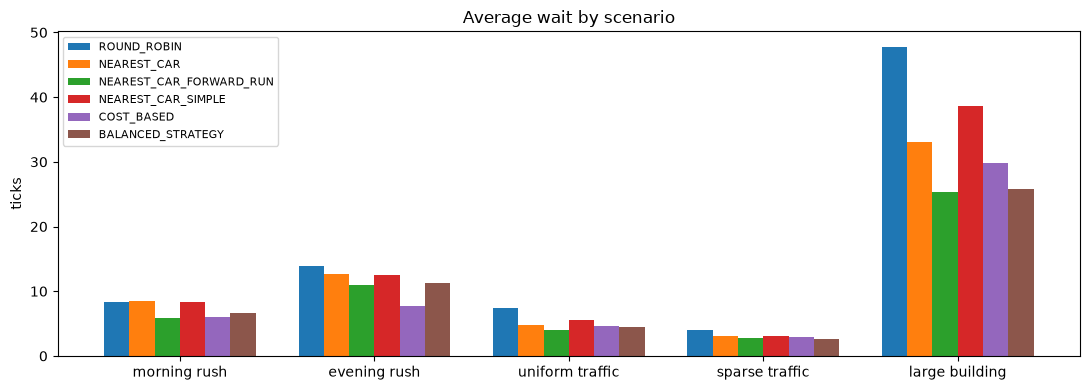

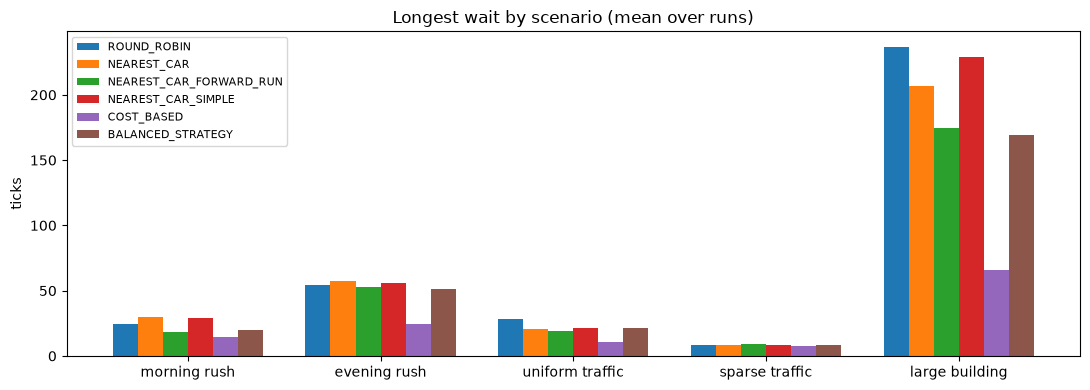

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

results = json.loads(Path("docs/scenario_results.json").read_text(encoding="utf-8"))

for scenario, data in results.items():
    print(f"{scenario} ({data['seeds']} seeds)")
    print(f"{'strategy':28}{'avg wait':>9}{'max wait':>9}{'floors':>8}{'balance':>9}")
    for name, m in sorted(data["strategies"].items(), key=lambda kv: kv[1]["avg_wait"]["mean"]):
        print(f"{name:28}{m['avg_wait']['mean']:>9.2f}{m['max_wait']['mean']:>9.1f}"
              f"{m['floors']['mean']:>8.1f}{m['balance']['mean']:>9.3f}")
    print()


def grouped_bars(measure, title, ylabel):
    """One group of bars per scenario, one bar per strategy."""
    names = list(next(iter(results.values()))["strategies"])
    width = 0.13
    fig, ax = plt.subplots(figsize=(11, 4))
    for i, name in enumerate(names):
        values = [results[s]["strategies"][name][measure]["mean"] for s in results]
        ax.bar([x + i * width for x in range(len(results))], values, width, label=name)
    ax.set_xticks([x + width * (len(names) - 1) / 2 for x in range(len(results))])
    ax.set_xticklabels(list(results))
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


grouped_bars("avg_wait", "Average wait by scenario", "ticks")
grouped_bars("max_wait", "Longest wait by scenario (mean over runs)", "ticks")
